# UJIAN TENGAH SEMESTER DATA MINING
## Klasifikasi Prediksi Kualitas Anggur (Wine Quality)

**Nama:** Inayah Syafa Shalihah Prayitno
**NIM:** 2404010020  
**Program Studi:** Statistika Terapan dan Komputasi  
**Mata Kuliah:** Data Mining  
**Dosen Pengampu:** Nur Achmey Selgi Harwanti, M.Stat

### Deskripsi
Analisis ini bertujuan untuk membangun model klasifikasi yang dapat memprediksi kualitas anggur (*Wine Quality*) berdasarkan karakteristik kimiawi yang terdapat pada dataset. Model dibangun menggunakan data training dan selanjutnya digunakan untuk memprediksi kualitas anggur pada data testing.

### 1. Import Library
Penjelasan:
Tahap pertama adalah melakukan impor beberapa library Python yang diperlukan untuk proses analisis data dan pemodelan klasifikasi. Library Pandas dan NumPy digunakan untuk pengolahan data, Matplotlib dan Seaborn untuk visualisasi, sedangkan Scikit learn digunakan untuk preprocessing, pembagian data, serta evaluasi model.

In [4]:
# Import Library

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Library untuk preprocessing dan pemodelan
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Mengatur tampilan visualisasi
sns.set_theme(style="whitegrid")

print("Semua library berhasil diimpor!")

Semua library berhasil diimpor!


Seluruh library berhasil diimpor, maka proses analisis data, visualisasi, preprocessing, dan pembangunan model klasifikasi dapat dilanjutkan.

### 2. Memuat Dataset
Penjelasan: Dataset yang digunakan dalam penelitian ini ada dua, yaitu data training dan data testing. Data training digunakan untuk membangun model klasifikasi karena memiliki variabel target berupa quality. Sementara itu, data testing digunakan untuk menguji model dalam menghasilkan prediksi kualitas anggur berdasarkan fitur kimiawi yang tersedia.

In [5]:
from google.colab import files

uploaded = files.upload()

Saving data_training.csv to data_training.csv
Saving data_testing.csv to data_testing.csv


Dataset training dan testing berhasil dimuat ke dalam Google Colab menggunakan Pandas. Kedua dataset selanjutnya digunakan dalam tahapan eksplorasi dan pengolahan data.

### 3. Melihat Lima Data Pertama
Penjelasan:
Tahapan ini dilakukan untuk melihat lima baris pertama dari masing-masing dataset menggunakan fungsi head(). Pemeriksaan awal bertujuan untuk mengetahui gambaran data, nama variabel, serta struktur informasi yang tersedia.

In [49]:
# Membaca dataset
df_train = pd.read_csv('data_training.csv')
df_test = pd.read_csv('data_testing.csv')

# Menampilkan 5 data pertama
print("DATA TRAINING")
display(df_train.head())

print("DATA TESTING")
display(df_test.head())

DATA TRAINING


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.3,0.740,0.08,1.7,0.094,10.0,45.0,0.99576,3.24,0.50,9.8,5,1366
1,8.1,0.575,0.22,2.1,0.077,12.0,65.0,0.99670,3.29,0.51,9.2,5,103
2,10.1,0.430,0.40,2.6,0.092,13.0,52.0,0.99834,3.22,0.64,10.0,7,942
3,12.9,0.500,0.55,2.8,0.072,7.0,24.0,1.00012,3.09,0.68,10.9,6,811
4,8.4,0.360,0.32,2.2,0.081,32.0,79.0,0.99640,3.30,0.72,11.0,6,918


DATA TESTING


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,Id
0,6.8,0.61,0.04,1.5,0.057,5.0,10.0,0.99525,3.42,0.60,9.500000,222
1,6.9,0.84,0.21,4.1,0.074,16.0,65.0,0.99842,3.53,0.72,9.233333,1514
2,7.0,0.58,0.12,1.9,0.091,34.0,124.0,0.99560,3.44,0.48,10.500000,417
3,7.8,0.48,0.68,1.7,0.415,14.0,32.0,0.99656,3.09,1.06,9.100000,754
4,12.5,0.60,0.49,4.3,0.100,5.0,14.0,1.00100,3.25,0.74,11.900000,516


Berdasarkan lima data pertama yang ditampilkan, dataset training dan testing memiliki 11 variabel karakteristik kimiawi anggur, seperti tingkat keasaman, kandungan gula, sulfur dioksida, kepadatan, pH, dan alkohol. Dataset training memiliki variabel tambahan quality sebagai target klasifikasi serta Id sebagai identitas data. Sementara itu, dataset testing tidak memiliki variabel quality karena akan digunakan untuk proses prediksi. Setiap sampel memiliki nilai karakteristik yang bervariasi sehingga dapat digunakan sebagai informasi untuk membangun model klasifikasi kualitas anggur.

### 4. Pemeriksaan Struktur Dataset
Pemeriksaan struktur dataset dilakukan menggunakan atribut shape dan fungsi info(). Atribut shape digunakan untuk mengetahui jumlah baris dan kolom, sedangkan info() digunakan untuk mengetahui nama variabel, tipe data, dan jumlah data non null pada setiap kolom.

In [50]:
print("Ukuran Data Training:", df_train.shape)
print("Ukuran Data Testing:", df_test.shape)

print("\nInformasi Data Training:")
df_train.info()

print("\nInformasi Data Testing:")
df_test.info()

Ukuran Data Training: (857, 13)
Ukuran Data Testing: (286, 12)

Informasi Data Training:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 857 entries, 0 to 856
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         857 non-null    float64
 1   volatile acidity      857 non-null    float64
 2   citric acid           857 non-null    float64
 3   residual sugar        857 non-null    float64
 4   chlorides             857 non-null    float64
 5   free sulfur dioxide   857 non-null    float64
 6   total sulfur dioxide  857 non-null    float64
 7   density               857 non-null    float64
 8   pH                    857 non-null    float64
 9   sulphates             857 non-null    float64
 10  alcohol               857 non-null    float64
 11  quality               857 non-null    int64  
 12  Id                    857 non-null    int64  
dtypes: float64(11), int64(2)
memory usag

- Berdasarkan hasil pemeriksaan struktur dataset, diperoleh 857 baris dan 13 kolom pada data training serta 286 baris dan 12 kolom pada data testing.
- Seluruh kolom memiliki jumlah data non-null yang sesuai dengan jumlah barisnya, sehingga tidak ditemukan missing values pada pemeriksaan awal.
- Sebagian besar variabel memiliki tipe data float64, sedangkan variabel quality dan Id bertipe int64. Tipe data tersebut menunjukkan bahwa dataset telah memiliki format numerik yang dapat digunakan dalam proses analisis dan pemodelan.
- Perbedaan jumlah kolom disebabkan oleh tidak adanya variabel target quality pada dataset testing.

## 5. Exploratory Data Analysis (EDA)
### 5.1 Statistik Deskriptif
Penjelasan: Statistik deskriptif dilakukan untuk mengetahui gambaran umum data melalui nilai rata-rata (mean), standar deviasi, nilai minimum, maksimum, serta kuartil dari setiap variabel numerik.

In [51]:
# Menampilkan statistik deskriptif
df_train.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
count,857.000000,857.000000,857.000000,857.000000,857.000000,857.000000,857.000000,857.000000,857.000000,857.000000,857.000000,857.000000,857.000000
mean,8.261960,0.529393,0.267351,2.506184,0.086830,15.782964,45.978413,0.996692,3.313092,0.656709,10.430338,5.653442,813.749125
std,1.701992,0.179162,0.195144,1.293512,0.048721,10.300402,31.692113,0.001901,0.152079,0.167364,1.066971,0.821777,463.807063
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.390000,8.400000,3.000000,0.000000
25%,7.100000,0.395000,0.090000,1.900000,0.070000,7.000000,21.000000,0.995520,3.210000,0.550000,9.500000,5.000000,413.000000
50%,7.900000,0.520000,0.250000,2.200000,0.079000,14.000000,38.000000,0.996680,3.310000,0.620000,10.200000,6.000000,814.000000
75%,9.100000,0.640000,0.420000,2.600000,0.090000,21.000000,63.000000,0.997800,3.400000,0.730000,11.100000,6.000000,1214.000000
max,15.600000,1.580000,1.000000,15.500000,0.611000,68.000000,278.000000,1.003200,4.010000,2.000000,14.000000,8.000000,1597.000000


Berdasarkan hasil statistik deskriptif, seluruh variabel memiliki jumlah data sebanyak 857 sampel, sehingga tidak terdapat perbedaan jumlah observasi pada setiap kolom.

- Nilai rata-rata (mean) kualitas anggur (quality) adalah 5,65 dengan nilai minimum 3 dan maksimum 8. Sementara itu, kadar alkohol (alcohol) memiliki rata-rata sebesar 10,43 dan kandungan residual sugar memiliki rata-rata sebesar 2,51.

- Nilai standar deviasi (std) menunjukkan adanya variasi pada setiap variabel. Perbedaan rentang nilai antarfitur juga menunjukkan bahwa skala data cukup beragam, sehingga perlu dipertimbangkan dalam tahap preprocessing, khususnya penerapan feature scaling.

### 5.2 Distribusi Kualitas Anggur
Penjelasan: Analisis distribusi dilakukan untuk mengetahui jumlah sampel pada setiap kategori kualitas anggur (quality). Visualisasi ini membantu melihat persebaran kelas target yang akan digunakan dalam pemodelan klasifikasi.

quality
3      6
4     26
5    362
6    341
7    109
8     13
Name: count, dtype: int64


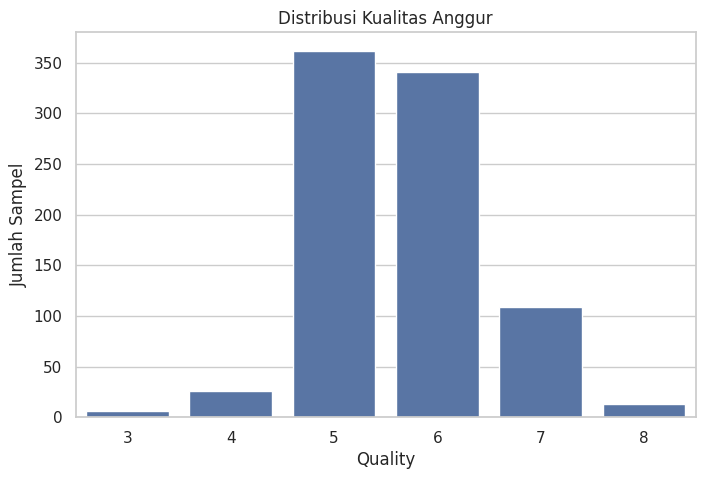

In [52]:
# Menghitung jumlah setiap kategori quality
print(df_train['quality'].value_counts().sort_index())

# Visualisasi distribusi quality
plt.figure(figsize=(8, 5))
sns.countplot(data=df_train, x='quality')

plt.title('Distribusi Kualitas Anggur')
plt.xlabel('Quality')
plt.ylabel('Jumlah Sampel')
plt.show()

Berdasarkan hasil visualisasi, kualitas anggur pada dataset training memiliki enam kategori, yaitu nilai 3 hingga 8. Kategori kualitas 5 memiliki jumlah sampel terbanyak sebanyak 362 data, diikuti kualitas 6 sebanyak 341 data dan kualitas 7 sebanyak 109 data.

Sementara itu, kategori kualitas 3 dan 8 memiliki jumlah sampel paling sedikit, masing-masing sebanyak 6 dan 13 data. Hal ini menunjukkan bahwa distribusi kelas target belum seimbang (imbalanced data), karena sebagian besar sampel terkonsentrasi pada kualitas 5 dan 6.

### 5.3 Distribusi Fitur
Penjelasan: Visualisasi distribusi fitur dilakukan untuk mengetahui pola penyebaran nilai pada setiap variabel kimiawi anggur. Analisis ini menggunakan histogram untuk melihat bentuk distribusi dan variasi nilai masing-masing fitur.

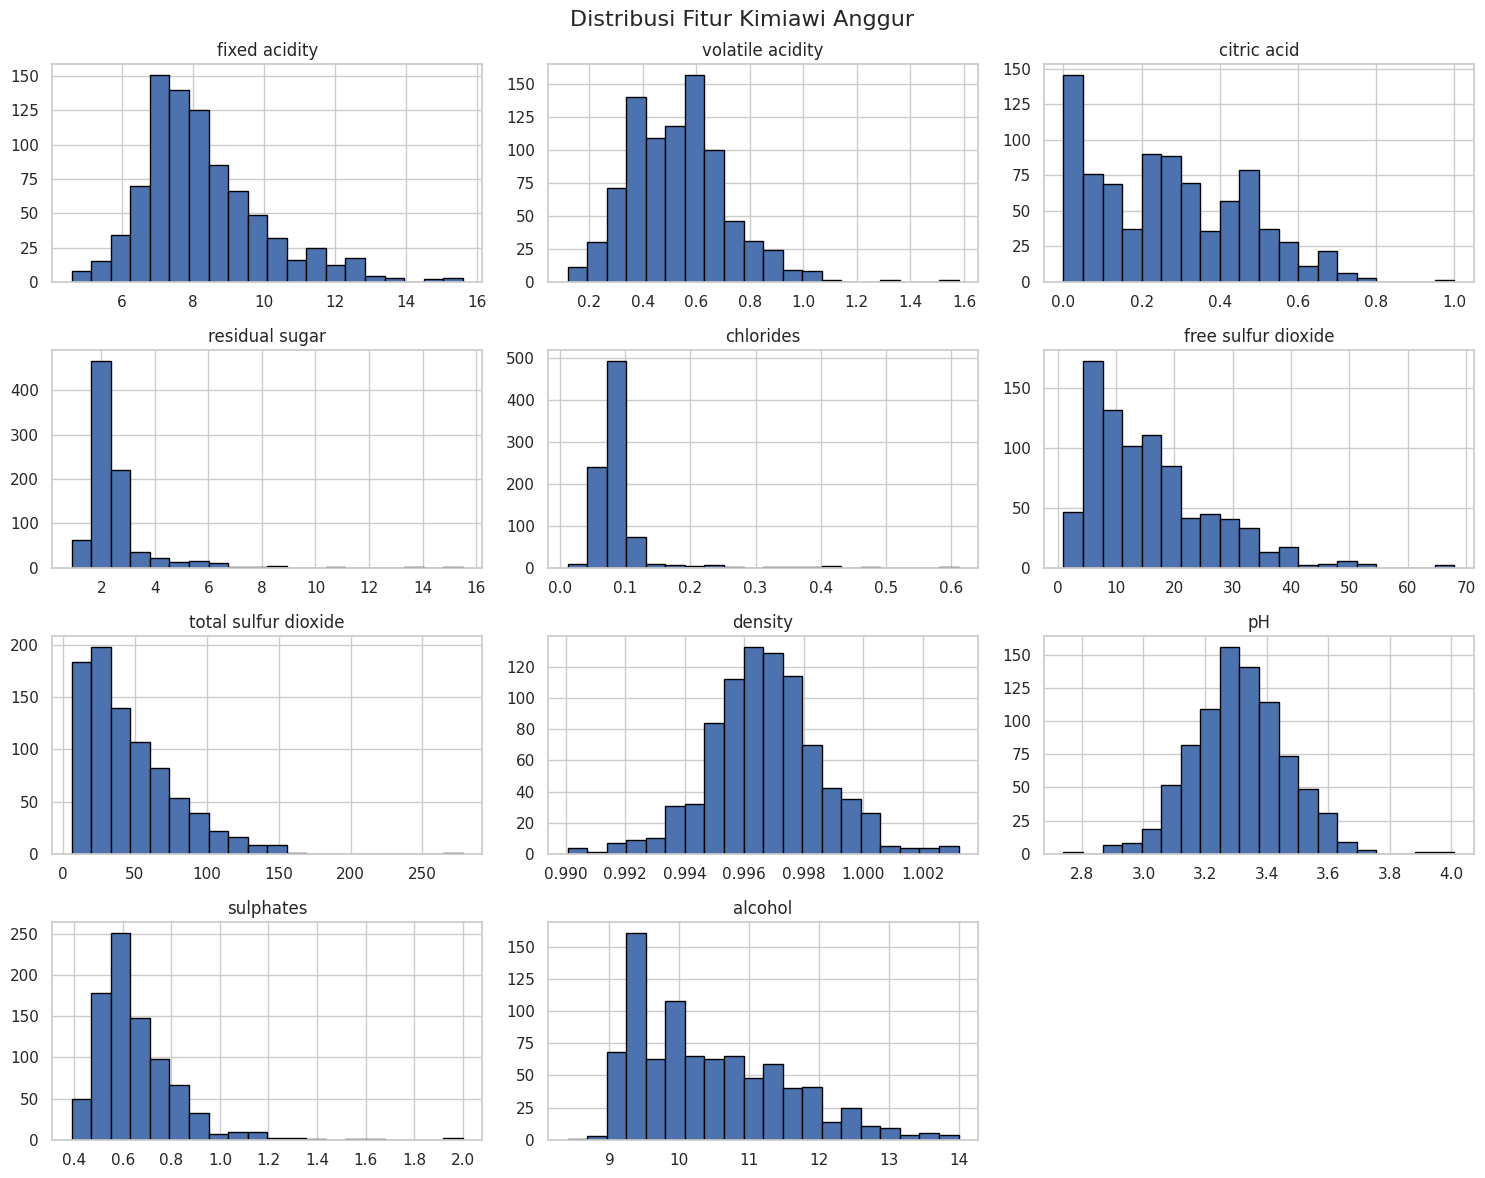

In [53]:
# Memilih fitur tanpa kolom Id dan quality
features = df_train.drop(columns=['Id', 'quality'])

# Membuat histogram setiap fitur
features.hist(figsize=(15, 12), bins=20, edgecolor='black')

plt.suptitle('Distribusi Fitur Kimiawi Anggur', fontsize=16)
plt.tight_layout()
plt.show()

- Berdasarkan visualisasi histogram, diketahui bahwa setiap fitur memiliki pola distribusi yang berbeda. Beberapa fitur seperti fixed acidity, volatile acidity, residual sugar, chlorides, free sulfur dioxide, total sulfur dioxide, dan sulphates menunjukkan distribusi yang menceng ke kanan (positive skewness).
- Fitur density dan pH memiliki distribusi yang relatif mendekati bentuk normal. Fitur citric acid dan alcohol juga menunjukkan variasi persebaran nilai yang cukup beragam.
- Beberapa fitur memiliki nilai ekstrem (outlier), terutama pada residual sugar, chlorides, dan total sulfur dioxide.

### 5.4 Korelasi Antar Variabel
Penjelasan: Analisis korelasi dilakukan untuk mengetahui hubungan antarvariabel numerik, termasuk hubungan antara fitur kimiawi dengan variabel target quality. Visualisasi menggunakan correlation heatmap dengan nilai korelasi berkisar antara -1 hingga 1.

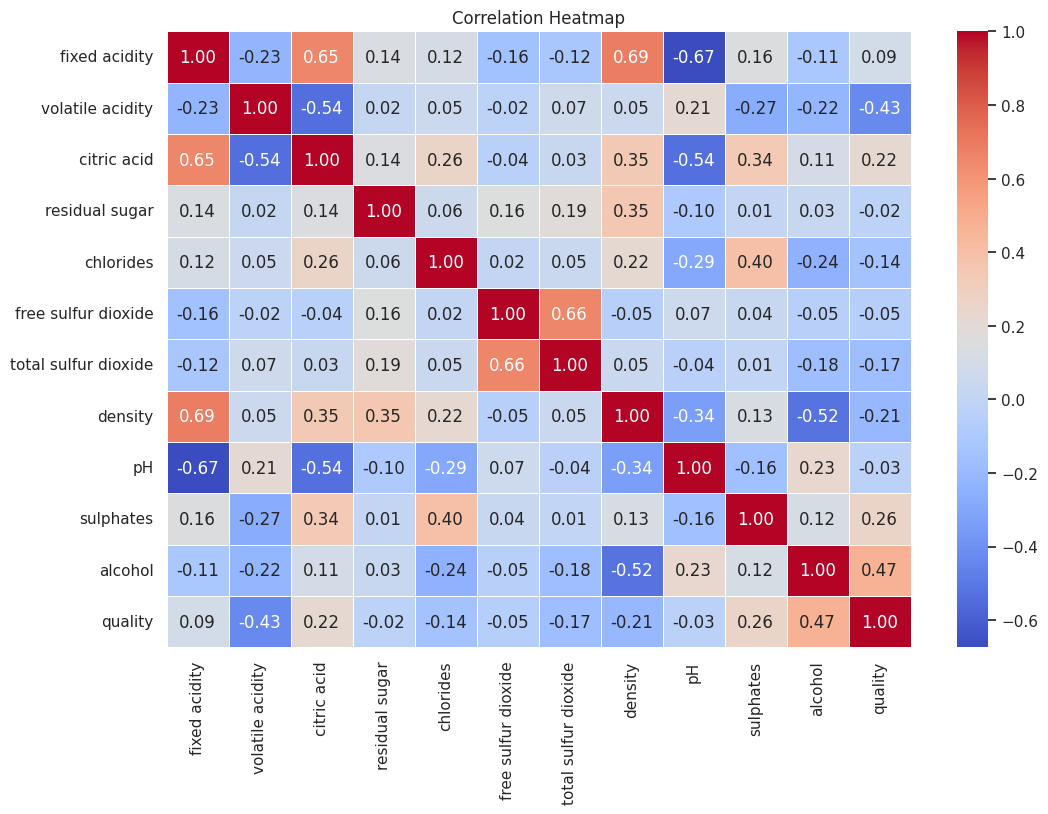

In [54]:
# Menghitung korelasi antarvariabel
correlation = df_train.drop(columns=['Id']).corr()

# Membuat visualisasi heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')
plt.show()

- Berdasarkan visualisasi correlation heatmap, diketahui bahwa setiap variabel memiliki tingkat hubungan yang berbeda terhadap kualitas anggur (quality).
- Fitur yang memiliki korelasi positif paling kuat dengan quality adalah alcohol sebesar 0,47, diikuti sulphates sebesar 0,26 dan citric acid sebesar 0,22. Hal ini menunjukkan bahwa ketiga fitur tersebut memiliki hubungan positif dengan kualitas anggur.
- Sementara itu, volatile acidity memiliki korelasi negatif paling kuat sebesar -0,43, yang menunjukkan hubungan berlawanan arah dengan kualitas anggur.

## 6. Pembersihan Dataa
### 6.1 Pemeriksaan Missing Values
Penjelasan: Pemeriksaan missing values dilakukan untuk memastikan tidak terdapat nilai kosong pada dataset training dan testing yang dapat memengaruhi proses pemodelan.

In [55]:
print("Missing Values Data Training:")
print(df_train.isnull().sum())

print("\nMissing Values Data Testing:")
print(df_test.isnull().sum())

Missing Values Data Training:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id                      0
dtype: int64

Missing Values Data Testing:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
Id                      0
dtype: int64


Berdasarkan hasil pemeriksaan, seluruh kolom pada dataset training (857 data) dan testing (286 data) memiliki jumlah missing values sebanyak 0. Hal ini menunjukkan bahwa tidak terdapat nilai kosong pada kedua dataset, sehingga tidak diperlukan penanganan khusus seperti penghapusan baris maupun imputasi data.

### 6.2 Pemeriksaan Data Duplikat
Penjelasan: Pemeriksaan data duplikat dilakukan untuk mengetahui apakah terdapat baris data yang memiliki nilai identik. Langkah ini bertujuan menghindari pengulangan data yang dapat memengaruhi hasil analisis.

In [56]:
print("Duplikat Data Training:",
      df_train.duplicated().sum())

print("Duplikat Data Testing:",
      df_test.duplicated().sum())

Duplikat Data Training: 0
Duplikat Data Testing: 0


Berdasarkan hasil pemeriksaan, dataset training dan testing masing-masing memiliki 0 data duplikat. Hal ini menunjukkan bahwa tidak terdapat baris data yang memiliki nilai identik pada kedua dataset. Dengan demikian, tidak diperlukan penghapusan data duplikat karena seluruh sampel sudah memiliki keunikan masing-masing.

### 6.3 Pemisahan Fitur dan Target
Penjelasan: Pemisahan fitur dan target dilakukan untuk menentukan variabel prediktor dan variabel yang akan diprediksi. Pada penelitian ini, kolom quality digunakan sebagai target klasifikasi, sedangkan kolom lainnya digunakan sebagai fitur. Kolom Id tidak digunakan karena hanya berfungsi sebagai identitas data.

In [57]:
# Memisahkan fitur dan target data training
X_train = df_train.drop(columns=['Id', 'quality'])
y_train = df_train['quality']

# Menghapus kolom Id pada data testing
X_test = df_test.drop(columns=['Id'])

# Menampilkan ukuran data
print("Ukuran X_train:", X_train.shape)
print("Ukuran y_train:", y_train.shape)
print("Ukuran X_test:", X_test.shape)

Ukuran X_train: (857, 11)
Ukuran y_train: (857,)
Ukuran X_test: (286, 11)


Berdasarkan hasil pemisahan data, diperoleh 857 sampel training dengan 11 variabel fitur (X_train) dan 857 nilai target (y_train). Sementara itu, data testing terdiri dari 286 sampel dengan 11 variabel fitur (X_test). Kolom quality digunakan sebagai variabel target yang akan diprediksi, sedangkan kolom Id dihapus karena hanya berfungsi sebagai identitas data.

### 6.4 Feature Scaling
Penjelasan: Feature scaling merupakan proses menyamakan skala nilai antarfitur agar tidak terdapat variabel dengan rentang nilai yang terlalu dominan. Pada tahap ini digunakan metode StandardScaler untuk mengubah data sehingga memiliki rata-rata mendekati 0 dan standar deviasi mendekati 1.

In [58]:
# Import StandardScaler
from sklearn.preprocessing import StandardScaler

# Membuat objek scaler
scaler = StandardScaler()

# Melakukan standardisasi data training dan testing
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Menampilkan ukuran data setelah scaling
print("Ukuran X_train_scaled:", X_train_scaled.shape)
print("Ukuran X_test_scaled:", X_test_scaled.shape)

# Menampilkan rata-rata fitur setelah scaling
print("Rata-rata fitur:", X_train_scaled.mean(axis=0))

Ukuran X_train_scaled: (857, 11)
Ukuran X_test_scaled: (286, 11)
Rata-rata fitur: [ 2.92259410e-16 -2.28003795e-16  1.05710850e-16 -8.29104709e-17
  2.25931033e-16  2.28003795e-17 -3.93824737e-17  4.87513569e-14
  2.13287186e-15 -4.06261307e-16  0.00000000e+00]


- Berdasarkan hasil standardisasi menggunakan metode StandardScaler, ukuran data training tetap sebanyak 857 baris dan 11 fitur, sedangkan data testing sebanyak 286 baris dan 11 fitur.
- Nilai rata-rata seluruh fitur setelah standardisasi mendekati 0. Hal ini menunjukkan bahwa proses penskalaan berhasil mengubah skala setiap variabel sehingga memiliki rata-rata mendekati 0 dan standar deviasi 1.
- Standardisasi dilakukan menggunakan parameter dari data training, kemudian diterapkan pada data testing untuk menghindari data leakage.

## 7. Pembagian Data (Data Splitting)
### 7.1 Pembagian Data Training dan Validasi
Pembagian data dilakukan untuk memisahkan data menjadi data pelatihan (training) dan data validasi (validation). Data training digunakan untuk membangun model, sedangkan data validasi digunakan untuk mengevaluasi kemampuan model dalam memprediksi data yang belum pernah dipelajari. Pada penelitian ini, data dibagi dengan perbandingan 80:20 menggunakan train_test_split. Parameter stratify digunakan agar proporsi setiap kelas kualitas anggur tetap terjaga.

In [59]:
from sklearn.model_selection import train_test_split

X_train_split, X_val_split, y_train_split, y_val_split = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Ukuran data training:", X_train_split.shape)
print("Ukuran data validasi:", X_val_split.shape)
print("Ukuran target training:", y_train_split.shape)
print("Ukuran target validasi:", y_val_split.shape)

Ukuran data training: (685, 11)
Ukuran data validasi: (172, 11)
Ukuran target training: (685,)
Ukuran target validasi: (172,)


Berdasarkan hasil pembagian data, diperoleh 685 data training dengan 11 fitur dan 172 data validasi dengan 11 fitur. Sementara itu, target training berjumlah 685 data dan target validasi berjumlah 172 data. Pembagian ini menggunakan proporsi 80:20 dengan parameter stratify untuk mempertahankan proporsi kelas kualitas anggur pada kedua kelompok data.

### 7.2 Scaling Setelah Pembagian Data
Supaya tidak terjadi data leakage, scaler hanya dipelajari dari data training hasil pembagian, kemudian diterapkan ke data validasi.

In [60]:
scaler_split = StandardScaler()

X_train_split_scaled = scaler_split.fit_transform(X_train_split)
X_val_split_scaled = scaler_split.transform(X_val_split)

print("Ukuran data training setelah scaling:", X_train_split_scaled.shape)
print("Ukuran data validasi setelah scaling:", X_val_split_scaled.shape)

Ukuran data training setelah scaling: (685, 11)
Ukuran data validasi setelah scaling: (172, 11)


Proses scaling menghasilkan 685 data training dan 172 data validasi, masing-masing dengan 11 fitur. StandardScaler diterapkan dengan mempelajari nilai rata-rata dan standar deviasi dari data training, kemudian menggunakan parameter tersebut untuk mentransformasi data validasi. Dengan demikian, seluruh fitur memiliki skala yang lebih seragam dan proses evaluasi terhindar dari kebocoran informasi (data leakage).

## 8. Pemodelan Klasifikasi
### 8.1 Import Library Pemodelan
Penjelasan: Tahap ini dilakukan dengan mengimpor algoritma klasifikasi yang akan digunakan. Decision Tree dan Random Forest merupakan algoritma berbasis pohon keputusan, sedangkan KNN melakukan klasifikasi berdasarkan kedekatan jarak antar data.

In [61]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

Library berhasil diimpor dan siap digunakan untuk membangun tiga model klasifikasi, yaitu Decision Tree, Random Forest, dan KNN.

### 8.2 Membangun Model Klasifikasi
Penjelasan: Setelah mengimpor algoritma, langkah selanjutnya adalah membangun model menggunakan data training hasil pembagian. Setiap model dilatih untuk mengenali pola hubungan antara karakteristik kimiawi anggur dengan kategori kualitasnya.

In [62]:
# Inisialisasi model
models = {
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5)
}

# Melatih setiap model
for name, model in models.items():
    model.fit(X_train_split_scaled, y_train_split)
    print(f"{name} berhasil dilatih.")

Decision Tree berhasil dilatih.
Random Forest berhasil dilatih.
KNN berhasil dilatih.


Model Decision Tree, Random Forest, dan KNN dilatih menggunakan 685 data training yang telah melalui proses scaling. Ketiga model akan digunakan untuk memprediksi kualitas anggur pada data validasi.

### 8.3 Evaluasi Model
Penjelasan: Evaluasi dilakukan untuk mengetahui kemampuan masing-masing model dalam mengklasifikasikan kualitas anggur. Pengukuran performa menggunakan Accuracy dan F1-Score. Macro F1-Score turut digunakan karena distribusi kelas kualitas anggur pada data training tidak seimbang.

In [63]:
from sklearn.metrics import accuracy_score, f1_score

results = []

for name, model in models.items():
    y_pred = model.predict(X_val_split_scaled)

    accuracy = accuracy_score(y_val_split, y_pred)
    macro_f1 = f1_score(y_val_split, y_pred, average='macro')

    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Macro F1-Score': macro_f1
    })

hasil_evaluasi = pd.DataFrame(results)
hasil_evaluasi

,Model,Accuracy,Macro F1-Score
0,Decision Tree,0.598837,0.367089
1,Random Forest,0.616279,0.369930
2,KNN,0.482558,0.248955


Berdasarkan hasil evaluasi, model Random Forest memperoleh nilai Accuracy tertinggi sebesar 61,63% dan Macro F1-Score sebesar 0,3699. Decision Tree memperoleh Accuracy sebesar 59,88% dengan Macro F1-Score 0,3671, sedangkan KNN menghasilkan Accuracy sebesar 48,26% dengan Macro F1-Score 0,2490.

Hasil tersebut menunjukkan bahwa Random Forest memiliki performa terbaik dibandingkan kedua algoritma lainnya. Meskipun demikian, nilai Macro F1-Score ketiga model masih relatif rendah. Hal ini menunjukkan bahwa kemampuan model dalam mengklasifikasikan setiap kelas kualitas anggur belum merata, terutama pada kelas dengan jumlah data yang lebih sedikit.

## 8.4 Evaluasi lebih lanjut untuk model terbaik
Sebelum memutuskan model akhir, perlu untuk melihat hasil klasifikasi Random Forest secara lebih rinci menggunakan classification report dan confusion matrix.
### 8.4.1 Classification Report
Penjelasan: Classification report digunakan untuk mengetahui performa model berdasarkan nilai Precision, Recall, dan F1-Score pada setiap kelas kualitas anggur.

In [64]:
from sklearn.metrics import classification_report

# Prediksi menggunakan Random Forest
y_pred_rf = models['Random Forest'].predict(X_val_split_scaled)

print(classification_report(y_val_split, y_pred_rf))

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         5
           5       0.67      0.79      0.72        73
           6       0.57      0.57      0.57        68
           7       0.50      0.36      0.42        22
           8       1.00      0.33      0.50         3

    accuracy                           0.62       172
   macro avg       0.46      0.34      0.37       172
weighted avg       0.59      0.62      0.60       172



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


- Berdasarkan hasil classification report, model Random Forest memperoleh nilai weighted average Precision sebesar 0,59, Recall sebesar 0,62, dan F1-Score sebesar 0,60. Sementara itu, nilai macro average F1-Score hanya sebesar 0,37.
- Pada kelas kualitas 5, model memperoleh F1-Score sebesar 0,72, sedangkan kelas 6 memperoleh 0,57. Kelas 7 dan 8 masing-masing memperoleh F1-Score sebesar 0,42 dan 0,50. Sementara itu, kelas 3 dan 4 memperoleh F1-Score sebesar 0,00 karena model belum berhasil memprediksi kedua kelas tersebut dengan benar.
- Hal ini menunjukkan bahwa model lebih baik dalam mengenali kelas yang memiliki jumlah data lebih banyak dibandingkan kelas minoritas. Kondisi tersebut berkaitan dengan distribusi kelas target yang tidak seimbang.

### 8.4.2 Confusion Matrix
Penjelasan: Confusion matrix digunakan untuk membandingkan kelas aktual dengan kelas hasil prediksi. Matriks ini membantu mengetahui jumlah prediksi yang benar maupun kesalahan klasifikasi pada setiap kelas.

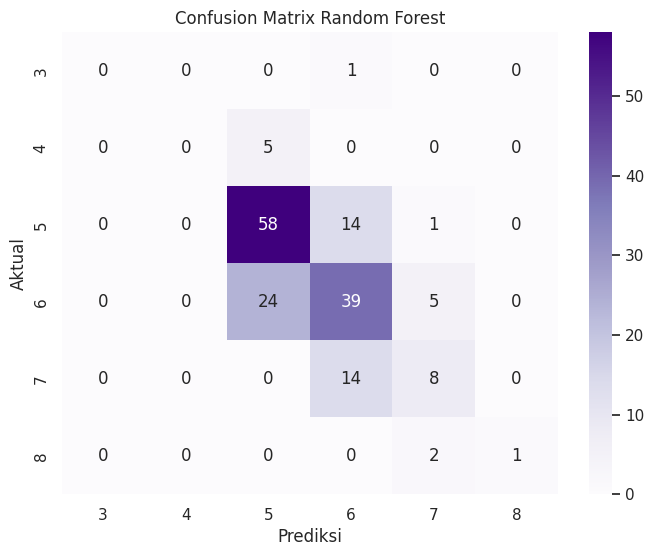

In [65]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_val_split, y_pred_rf)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Purples',
    xticklabels=sorted(y_train.unique()),
    yticklabels=sorted(y_train.unique())
)

plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title('Confusion Matrix Random Forest')
plt.show()

Berdasarkan confusion matrix, model Random Forest berhasil mengklasifikasikan 106 dari 172 data validasi dengan benar. Hasil tersebut menunjukkan bahwa sebagian besar prediksi benar berasal dari kelas kualitas 5 dan 6.

Beberapa kesalahan klasifikasi yang terlihat antara lain:
- Dari 73 data aktual kelas 5, sebanyak 58 data diprediksi dengan benar sebagai kelas 5.
- Dari 68 data aktual kelas 6, sebanyak 39 data diprediksi dengan benar sebagai kelas 6, sedangkan 24 data salah diprediksi sebagai kelas 5.
- Dari 22 data aktual kelas 7, sebanyak 8 data diprediksi dengan benar sebagai kelas 7.
- Dari 3 data aktual kelas 8, hanya 1 data yang diprediksi dengan benar.
Kesalahan prediksi paling terlihat terjadi antara kelas 5 dan 6.

Hal ini menunjukkan bahwa model masih mengalami kesulitan membedakan kualitas anggur yang berada pada kategori berdekatan.

### 8.5 Optimasi Random Forest
Penjelasan: Optimasi model dilakukan untuk memperoleh kombinasi parameter Random Forest yang memberikan performa klasifikasi lebih baik. Proses pencarian menggunakan GridSearchCV dengan Stratified K-Fold Cross Validation sebanyak lima lipatan. Metode ini mempertahankan proporsi kelas pada setiap lipatan sehingga evaluasi lebih representatif.

In [30]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

# Menentukan kombinasi parameter
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'class_weight': [None, 'balanced']
}

# Inisialisasi model
rf = RandomForestClassifier(random_state=42)

# Cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Grid Search
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

# Melatih dan mencari parameter terbaik
grid_search.fit(X_train_split, y_train_split)

print("Parameter terbaik:")
print(grid_search.best_params_)

print("\nMacro F1-Score terbaik:")
print(grid_search.best_score_)

Fitting 5 folds for each of 72 candidates, totalling 360 fits
Parameter terbaik:
{'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}

Macro F1-Score terbaik:
0.3505947095592493


Berdasarkan proses GridSearchCV dengan 72 kombinasi parameter dan 5-fold cross-validation, diperoleh parameter terbaik sebagai berikut:

Parameter	                 =               Nilai terbaik

class_weight	             =              balanced

max_depth	                 =              10

min_samples_leaf	         =              2

min_samples_split	         =              5

n_estimators               =             	200

Model memperoleh Macro F1-Score rata-rata sebesar 0,3506 pada proses cross-validation. Hasil tersebut menunjukkan bahwa kombinasi parameter yang dipilih memberikan performa rata-rata tersebut dalam proses validasi silang.

### 8.6 Membandingkan Model Sebelum dan Sesudah Optimasi
Perbandingan dilakukan untuk mengetahui apakah optimasi parameter menghasilkan peningkatan performa model. Kedua model diuji menggunakan data validasi dengan metrik Accuracy dan Macro F1-Score.

In [31]:
from sklearn.metrics import accuracy_score, f1_score

# Model Random Forest awal
model_awal = models['Random Forest']

pred_awal = model_awal.predict(X_val_split_scaled)

# Model Random Forest hasil optimasi
model_optimasi = grid_search.best_estimator_

pred_optimasi = model_optimasi.predict(X_val_split)

# Membandingkan performa
perbandingan = pd.DataFrame({
    'Model': ['Random Forest Awal', 'Random Forest Optimasi'],
    'Accuracy': [
        accuracy_score(y_val_split, pred_awal),
        accuracy_score(y_val_split, pred_optimasi)
    ],
    'Macro F1-Score': [
        f1_score(y_val_split, pred_awal, average='macro'),
        f1_score(y_val_split, pred_optimasi, average='macro')
    ]
})

perbandingan

,Model,Accuracy,Macro F1-Score
0,Random Forest Awal,0.616279,0.36993
1,Random Forest Optimasi,0.558140,0.34198


Hasil pengujian menunjukkan bahwa Random Forest sebelum optimasi memperoleh Accuracy sebesar 61,63% dan Macro F1 sebesar 0,3699. Sementara itu, Random Forest setelah optimasi memperoleh Accuracy sebesar 55,81% dan Macro F1 sebesar 0,3420. Dengan demikian, optimasi hyperparameter belum mampu meningkatkan performa model pada data validasi. Model Random Forest awal masih memberikan hasil yang lebih baik berdasarkan kedua metrik evaluasi tersebut.

### 8.7 Pengujian Algoritma Klasifikasi Tambahan
Penjelasan: Untuk memperoleh alternatif model dengan performa yang lebih baik, dilakukan pengujian terhadap tiga algoritma klasifikasi tambahan, yaitu Support Vector Machine (SVM), Gradient Boosting, dan Extra Trees. Evaluasi menggunakan 5-Fold Cross-Validation dengan metrik Accuracy dan Macro F1. Penggunaan Macro F1 bertujuan untuk memperhatikan performa prediksi pada setiap kelas, termasuk kelas dengan jumlah data yang lebih sedikit.

In [32]:
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier, ExtraTreesClassifier
import pandas as pd

# Menentukan algoritma yang akan diuji
additional_models = {
    'SVM': make_pipeline(
        StandardScaler(),
        SVC()
    ),
    'Gradient Boosting': GradientBoostingClassifier(
        random_state=42
    ),
    'Extra Trees': ExtraTreesClassifier(
        n_estimators=300,
        random_state=42,
        class_weight='balanced'
    )
}

# Menentukan skema cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Melakukan pengujian setiap model
results = []

for name, model in additional_models.items():
    scores = cross_validate(
        model,
        X_train_split,
        y_train_split,
        cv=cv,
        scoring={
            'accuracy': 'accuracy',
            'macro_f1': 'f1_macro'
        },
        n_jobs=-1
    )

    results.append({
        'Model': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Macro F1': scores['test_macro_f1'].mean()
    })

# Menampilkan hasil pengujian
results_df = pd.DataFrame(results)
print(results_df.round(4))

               Model  Accuracy  Macro F1
0                SVM    0.6015    0.2786
1  Gradient Boosting    0.6161    0.3085
2        Extra Trees    0.6263    0.3031


Berdasarkan hasil pengujian menggunakan 5-Fold Cross-Validation, model Extra Trees memperoleh nilai Accuracy tertinggi sebesar 0,6263 (62,63%), sedangkan SVM memperoleh 60,15% dan Gradient Boosting sebesar 61,61%. Namun, berdasarkan Macro F1, Gradient Boosting memperoleh nilai tertinggi sebesar 0,3085, diikuti Extra Trees sebesar 0,3031 dan SVM sebesar 0,2786.

Hasil tersebut menunjukkan bahwa Extra Trees memiliki ketepatan prediksi keseluruhan paling tinggi di antara ketiga model, sedangkan Gradient Boosting memiliki keseimbangan performa yang sedikit lebih baik dalam memprediksi setiap kelas. Dengan demikian, kedua model tersebut dapat dipertimbangkan untuk pengujian lebih lanjut.

### 8.8 Perbandingan Seluruh Model Klasifikasi
Penjelasan: Tahap ini dilakukan untuk membandingkan performa seluruh algoritma klasifikasi yang telah diuji menggunakan metode 5-Fold Cross-Validation. Perbandingan dilakukan berdasarkan nilai Accuracy dan Macro F1 untuk mengetahui model yang memberikan performa terbaik dalam mengklasifikasikan kualitas wine.

In [33]:
from sklearn.model_selection import cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

all_models = {
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'SVM': make_pipeline(StandardScaler(), SVC()),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'Extra Trees': ExtraTreesClassifier(
        n_estimators=300,
        random_state=42,
        class_weight='balanced'
    )
}

comparison_results = []

for name, model in all_models.items():
    scores = cross_validate(
        model,
        X_train_split,
        y_train_split,
        cv=cv,
        scoring={
            'accuracy': 'accuracy',
            'macro_f1': 'f1_macro'
        },
        n_jobs=-1
    )

    comparison_results.append({
        'Model': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Macro F1': scores['test_macro_f1'].mean()
    })

comparison_df = pd.DataFrame(comparison_results)

print(comparison_df.sort_values(
    by='Macro F1', ascending=False
).round(4))

               Model  Accuracy  Macro F1
1      Random Forest    0.6350    0.3120
3  Gradient Boosting    0.6161    0.3085
4        Extra Trees    0.6263    0.3031
0      Decision Tree    0.5226    0.2797
2                SVM    0.6015    0.2786


Berdasarkan hasil pengujian menggunakan 5-Fold Cross-Validation, Random Forest memperoleh nilai Accuracy tertinggi sebesar 0,6350 (63,50%) dan Macro F1 sebesar 0,3120. Gradient Boosting memperoleh Accuracy sebesar 61,61% dan Macro F1 sebesar 0,3085, sedangkan Extra Trees memperoleh Accuracy sebesar 62,63% dan Macro F1 sebesar 0,3031.

Hasil tersebut menunjukkan bahwa Random Forest memiliki performa terbaik di antara lima algoritma yang diuji, baik berdasarkan Accuracy maupun Macro F1. Oleh karena itu, Random Forest dipilih sebagai kandidat model untuk tahap evaluasi selanjutnya.

### 8.9 Evaluasi model terpilih
Penjelasan: Random Forest dipilih sebagai model kandidat berdasarkan hasil perbandingan 5-Fold Cross-Validation. Selanjutnya, model dievaluasi menggunakan data validasi dengan metrik Accuracy, Classification Report, dan Confusion Matrix untuk mengetahui kemampuan model dalam mengklasifikasikan setiap kategori kualitas wine.

In [34]:
# Membuat dan melatih model Random Forest
best_model = RandomForestClassifier(random_state=42)

best_model.fit(X_train_split, y_train_split)

# Melakukan prediksi pada data validasi
y_val_pred = best_model.predict(X_val_split)

# Evaluasi model
print("Accuracy:", accuracy_score(y_val_split, y_val_pred))

print("\nClassification Report:")
print(classification_report(y_val_split, y_val_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_split, y_val_pred))

Accuracy: 0.6104651162790697

Classification Report:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         5
           5       0.66      0.79      0.72        73
           6       0.57      0.56      0.56        68
           7       0.50      0.36      0.42        22
           8       1.00      0.33      0.50         3

    accuracy                           0.61       172
   macro avg       0.45      0.34      0.37       172
weighted avg       0.59      0.61      0.59       172


Confusion Matrix:
[[ 0  0  0  1  0  0]
 [ 0  0  5  0  0  0]
 [ 0  0 58 14  1  0]
 [ 0  0 25 38  5  0]
 [ 0  0  0 14  8  0]
 [ 0  0  0  0  2  1]]


Berdasarkan hasil evaluasi pada 172 data validasi, model Random Forest memperoleh nilai Accuracy sebesar 61,05% dan Macro F1 sebesar 0,37. Model mampu mengklasifikasikan kualitas wine kategori 5 dengan cukup baik, yaitu memperoleh F1-score sebesar 0,72, diikuti kategori 6 sebesar 0,56 dan kategori 7 sebesar 0,42.

Namun, model belum mampu mengklasifikasikan kategori 3 dan 4 dengan benar. Hal ini menunjukkan bahwa model masih mengalami kesulitan dalam mengenali kelas dengan jumlah data yang sedikit. Berdasarkan confusion matrix, sebagian besar kesalahan prediksi terjadi pada kategori 5 dan 6 yang saling tertukar.

Secara keseluruhan, Random Forest memiliki performa yang cukup baik dalam mengenali kelas mayoritas, tetapi kemampuan klasifikasinya terhadap seluruh kategori masih perlu diperhatikan.

### 8.10 Optimasi Lanjutan Hyperparameter Random Forest
Penjelasan: Pada tahap ini dilakukan optimasi lanjutan terhadap algoritma Random Forest menggunakan RandomizedSearchCV. Optimasi bertujuan memperoleh kombinasi hyperparameter yang lebih optimal dengan mengeksplorasi berbagai konfigurasi model. Penilaian dilakukan menggunakan 5-Fold Cross-Validation dengan Macro F1 sebagai metrik utama.

In [38]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

param_dist = {
    'n_estimators': randint(100, 701),
    'max_depth': [None, 5, 10, 15, 20, 25, 30],
    'min_samples_split': randint(2, 16),
    'min_samples_leaf': randint(1, 9),
    'max_features': ['sqrt', 'log2', None],
    'class_weight': [None, 'balanced', 'balanced_subsample']
}

rf_model = RandomForestClassifier(random_state=42)

random_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=param_dist,
    n_iter=60,
    scoring='f1_macro',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train_split, y_train_split)

print("Parameter terbaik:")
print(random_search.best_params_)

print("\nBest Cross-Validation Macro F1:")
print(random_search.best_score_)

Fitting 5 folds for each of 60 candidates, totalling 300 fits
Parameter terbaik:
{'class_weight': 'balanced_subsample', 'max_depth': None, 'max_features': 'log2', 'min_samples_leaf': 2, 'min_samples_split': 13, 'n_estimators': 665}

Best Cross-Validation Macro F1:
0.3386440389579862


Hasil ini menunjukkan bahwa RandomizedSearchCV berhasil menemukan konfigurasi parameter dengan performa Macro F1 sebesar 0,3386 pada proses validasi silang. Hasil tersebut selanjutnya perlu dibandingkan dengan model Random Forest sebelumnya menggunakan data validasi untuk mengetahui apakah optimasi memberikan peningkatan performa.

### 8.11 Eksplorasi Hyperparameter Random Forest Lanjutan
Penjelasan: Pada tahap ini dilakukan optimasi lanjutan terhadap hyperparameter Random Forest menggunakan RandomizedSearchCV dengan Accuracy sebagai metrik utama. Pencarian dilakukan terhadap berbagai kombinasi parameter untuk memperoleh konfigurasi model yang memiliki kemampuan prediksi lebih baik.

In [39]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from scipy.stats import randint

param_dist_accuracy = {
    'n_estimators': randint(200, 1001),
    'max_depth': [None, 8, 10, 12, 15, 20, 25, 30, 40],
    'min_samples_split': randint(2, 21),
    'min_samples_leaf': randint(1, 11),
    'max_features': ['sqrt', 'log2', None],
    'criterion': ['gini', 'entropy', 'log_loss'],
    'class_weight': [None, 'balanced', 'balanced_subsample']
}

rf_accuracy = RandomForestClassifier(random_state=42)

random_search_accuracy = RandomizedSearchCV(
    estimator=rf_accuracy,
    param_distributions=param_dist_accuracy,
    n_iter=100,
    scoring='accuracy',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search_accuracy.fit(X_train_split, y_train_split)

print("Parameter terbaik:")
print(random_search_accuracy.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(random_search_accuracy.best_score_)

Fitting 5 folds for each of 100 candidates, totalling 500 fits
Parameter terbaik:
{'class_weight': 'balanced', 'criterion': 'log_loss', 'max_depth': 10, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split': 6, 'n_estimators': 715}

Best Cross-Validation Accuracy:
0.6394160583941606


Berdasarkan proses optimasi menggunakan RandomizedSearchCV dengan 100 kombinasi parameter dan 5-Fold Cross-Validation, diperoleh konfigurasi terbaik yaitu n_estimators=715, max_depth=10, max_features='log2', min_samples_leaf=1, min_samples_split=6, criterion='log_loss', dan class_weight='balanced'. Konfigurasi tersebut menghasilkan nilai rata-rata Accuracy sebesar 0,6394 atau 63,94%.

Hasil ini menunjukkan adanya peningkatan Accuracy dibandingkan pengujian Random Forest sebelumnya yang memperoleh 63,50% melalui 5-Fold Cross-Validation.

### 8.12 Optimasi Random Forest dengan Parameter Terarah.
Penjelasan: Pada tahap ini dilakukan optimasi lanjutan menggunakan RandomizedSearchCV dengan rentang hyperparameter yang lebih terarah berdasarkan hasil optimasi sebelumnya. Tujuannya adalah mengeksplorasi kombinasi parameter lain yang berpotensi meningkatkan akurasi model Random Forest.

In [40]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from scipy.stats import randint

param_dist_final = {
    'n_estimators': randint(500, 1001),
    'max_depth': [8, 10, 12, 15, 18, 20, None],
    'max_features': ['sqrt', 'log2'],
    'min_samples_split': randint(2, 11),
    'min_samples_leaf': randint(1, 5),
    'criterion': ['gini', 'entropy', 'log_loss'],
    'class_weight': [None, 'balanced', 'balanced_subsample']
}

rf_final_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_distributions=param_dist_final,
    n_iter=50,
    scoring='accuracy',
    cv=cv,
    random_state=123,
    n_jobs=-1,
    verbose=1
)

rf_final_search.fit(X_train_split, y_train_split)

print("Parameter terbaik:")
print(rf_final_search.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(rf_final_search.best_score_)

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Parameter terbaik:
{'class_weight': 'balanced_subsample', 'criterion': 'gini', 'max_depth': None, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split': 6, 'n_estimators': 920}

Best Cross-Validation Accuracy:
0.6496350364963502


## 9. Pelatihan Model Final dan Prediksi
Selanjutnya, setelah melakukan uji cba model, kandidat model terpilih yaitu Random Forest. Berikutnya akan dilakukan pelatihan model menggunakan seluruh data training (857 baris), kemudian memprediksi 286 data testing.

### 9.1 Evaluasi Model Random Forest Teroptimasi
Penjelasan: Model Random Forest dengan kombinasi hyperparameter terbaik dari proses optimasi lanjutan dipilih untuk digunakan pada tahap akhir. Sebelum diterapkan pada data testing, model dievaluasi menggunakan data validasi untuk mengetahui kemampuan klasifikasinya.

In [42]:
# Mengambil model dengan parameter terbaik
final_candidate = rf_final_search.best_estimator_

# Prediksi pada data validasi
y_val_pred_final = final_candidate.predict(X_val_split)

# Evaluasi model
print("Accuracy:",
      accuracy_score(y_val_split, y_val_pred_final))

print("\nClassification Report:")
print(classification_report(
    y_val_split,
    y_val_pred_final,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_split, y_val_pred_final))

Accuracy: 0.6046511627906976

Classification Report:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         5
           5       0.68      0.75      0.71        73
           6       0.57      0.60      0.59        68
           7       0.44      0.32      0.37        22
           8       1.00      0.33      0.50         3

    accuracy                           0.60       172
   macro avg       0.45      0.33      0.36       172
weighted avg       0.59      0.60      0.59       172


Confusion Matrix:
[[ 0  0  0  1  0  0]
 [ 0  0  5  0  0  0]
 [ 1  1 55 15  1  0]
 [ 0  0 21 41  6  0]
 [ 0  0  0 15  7  0]
 [ 0  0  0  0  2  1]]


Berdasarkan hasil evaluasi pada 172 data validasi, model Random Forest hasil optimasi memperoleh nilai Accuracy sebesar 60,47% dan Macro F1 sebesar 0,36. Model mampu mengklasifikasikan kategori kualitas 5 dengan F1-score sebesar 0,71, kategori 6 sebesar 0,59, kategori 7 sebesar 0,37, dan kategori 8 sebesar 0,50. Sementara itu, kategori 3 dan 4 belum berhasil diklasifikasikan dengan benar.

Hasil confusion matrix menunjukkan bahwa kesalahan prediksi paling banyak terjadi pada kategori 5 dan 6 yang saling tertukar. Hal ini menunjukkan bahwa model masih memiliki keterbatasan dalam membedakan beberapa kategori kualitas wine.
Mengapa Accuracy-nya berbeda dengan hasil optimasi sebelumnya?
Pada Tahap 8.12, diperoleh Accuracy sebesar 64,96%, sedangkan pada Tahap 9.1 diperoleh Accuracy sebesar 60,47%. Perbedaan ini terjadi karena kedua pengujian menggunakan pendekatan evaluasi yang berbeda.
- Tahap 8.12: Accuracy merupakan rata-rata hasil 5-Fold Cross-Validation dari lima pembagian data training.
- Tahap 9.1: Accuracy dihitung berdasarkan satu kali pengujian pada data validasi yang terdiri dari 172 baris data.
Dengan demikian, nilai Accuracy pada kedua tahap tidak harus sama. Perbedaan hasil tersebut menunjukkan bahwa performa model dapat bervariasi bergantung pada pembagian data yang digunakan.

### 9.2 Pelatihan Model final
Penjelasan: Melatih model dengan seluruh 857 data training menggunakan parameter terbaik Tahap 8.12.

In [43]:
# Mengambil model hasil optimasi
final_model = rf_final_search.best_estimator_

# Melatih ulang menggunakan seluruh data training
final_model.fit(X_train, y_train)

print("Model Random Forest final berhasil dilatih.")
print("Jumlah data training:", X_train.shape)
print("Jumlah data testing:", X_test.shape)

Model Random Forest final berhasil dilatih.
Jumlah data training: (857, 11)
Jumlah data testing: (286, 11)


Model Random Forest final berhasil dilatih menggunakan seluruh data training sebanyak 857 baris dengan 11 fitur. Proses pelatihan ulang dilakukan agar model dapat memanfaatkan seluruh informasi yang tersedia sebelum digunakan untuk memprediksi data testing sebanyak 286 baris dengan 11 fitur.

### 9.3 Prediksi data testing
Penjelasan: Model Random Forest final yang telah dilatih digunakan untuk memprediksi kategori kualitas wine pada seluruh data testing. Hasil prediksi kemudian digabungkan dengan kolom Id untuk menghasilkan data keluaran.

In [44]:
# Melakukan prediksi pada data testing
y_test_pred = final_model.predict(X_test)

# Membuat DataFrame hasil prediksi
hasil_prediksi = pd.DataFrame({
    'Id': df_test['Id'],
    'Quality': y_test_pred
})

# Menampilkan 10 hasil prediksi pertama
hasil_prediksi.head(10)

,Id,Quality
0,222,5
1,1514,6
2,417,5
3,754,5
4,516,6
5,1120,6
6,180,5
7,82,5
8,632,6
9,592,5


### 9.4 Menyimpan hasil prediksi

In [45]:
hasil_prediksi.to_csv('hasilprediksi_020.csv', index=False)

print("File hasilprediksi_020.csv berhasil disimpan.")

File hasilprediksi_020.csv berhasil disimpan.


Berdasarkan output yang diperoleh, file hasil prediksi berhasil disimpan dalam format CSV. File tersebut berisi identitas sampel (Id) dan hasil prediksi kualitas anggur (Quality) yang nantinya digunakan sebagai output akhir pengerjaan UTS.

## 10. Pemeriksaan akhir
### 10.1 Pemeriksaan hasil prediksi

In [46]:
hasil_cek = pd.read_csv('hasilprediksi_020.csv')

print("Ukuran file:", hasil_cek.shape)
print("Kolom:", hasil_cek.columns.tolist())
print("Missing values:", hasil_cek.isnull().sum().sum())
print("Duplikasi:", hasil_cek.duplicated().sum())

display(hasil_cek.head())

Ukuran file: (286, 2)
Kolom: ['Id', 'Quality']
Missing values: 0
Duplikasi: 0


,Id,Quality
0,222,5
1,1514,6
2,417,5
3,754,5
4,516,6


- Berdasarkan hasil pemeriksaan, file hasil prediksi memiliki ukuran 286 baris dan 2 kolom, yaitu Id dan Quality. Jumlah tersebut telah sesuai dengan jumlah data testing yang digunakan.
- Hasil pemeriksaan juga menunjukkan bahwa tidak terdapat nilai kosong pada kedua kolom maupun baris duplikat. Selain itu, lima data terakhir berhasil ditampilkan sebagai pemeriksaan tambahan terhadap hasil prediksi.
- Dengan demikian, file hasil prediksi telah memiliki struktur yang sesuai dengan ketentuan pengumpulan dan siap digunakan sebagai output akhir klasifikasi.

### 10.2 Mengunduh file csv

penjelasan: Setelah proses prediksi selesai, file hasil klasifikasi diunduh dari Google Colab ke perangkat lokal. File disimpan dalam format CSV dengan nama hasilprediksi_020.csv sesuai tiga digit terakhir NIM. File ini merupakan output akhir yang berisi hasil prediksi kualitas anggur pada data testing.

In [47]:
from google.colab import files
files.download('hasilprediksi_020.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Berdasarkan proses yang dilakukan, file hasilprediksi_020.csv berhasil diunduh dari Google Colab. File tersebut memuat hasil prediksi kualitas anggur untuk 286 data testing dan siap digunakan sebagai salah satu berkas pengumpulan UTS Data Mining.

### 10.3 Pengecekan file akhir csv
penjelasan: pengecekan akhir dilakukan untuk memastikan file CSV yang telah disimpan memiliki struktur sesuai ketentuan pengumpulan. Pemeriksaan dilakukan dengan membaca kembali file menggunakan fungsi pd.read_csv(), kemudian melihat ukuran data, nama kolom, dan beberapa baris pertama.

In [48]:
import pandas as pd

cek_csv = pd.read_csv('hasilprediksi_020.csv')

print(cek_csv.shape)
print(cek_csv.columns.tolist())
display(cek_csv.head())

(286, 2)
['Id', 'Quality']


,Id,Quality
0,222,5
1,1514,6
2,417,5
3,754,5
4,516,6


Berdasarkan hasil pengecekan, file CSV memiliki ukuran 286 baris dan 2 kolom dengan nama Id dan Quality. Hasil tersebut menunjukkan bahwa identitas sampel dan hasil prediksi telah tersimpan secara terpisah pada masing-masing kolom. Dengan demikian, struktur file telah sesuai dengan ketentuan pengumpulan dan dapat dibaca kembali menggunakan Python tanpa kesalahan.